<a href="https://colab.research.google.com/github/rahul18107/deep-learning/blob/main/1bm24cd054_assement_program_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Step 1 — Imports and the dataset

**Q. What do the two numbers in `data.shape` mean (rows vs columns)?**
* **First number (1200):** Represents the number of rows, which is the total number of independent music sequences in the dataset (`num_sequences`).
* **Second number (25):** Represents the number of columns, which is the length of each sequence (`sequence_length`).

In [5]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt

np.random.seed(7)
num_notes = 40
sequence_length = 25
num_sequences = 1200
data = np.random.randint(0, num_notes, size=(num_sequences, sequence_length))
print(data.shape)

(1200, 25)


### Step 2 — Build input/target pairs and one-hot encode

**Q. Why is the target the input shifted by one? What task does that set up?**
It sets up a next-note prediction task. At each time step $t$, the model's goal is to predict the next note in the sequence, which is the note located at $t+1$.

In [6]:
x_train = data[:, :-1]
y_train = data[:, 1:]
x_train = to_categorical(x_train, num_classes=40)
y_train = to_categorical(y_train, num_classes=40)
print("x_train :", x_train.shape, "y_train :", y_train.shape)

x_train : (1200, 24, 40) y_train : (1200, 24, 40)


### Step 3 — Build the Bidirectional LSTM model

**Q. Each LSTM has 100 units, yet each Bidirectional layer outputs 200 features per step — why? And what does TimeDistributed do with the Dense layer?**
* **200 features:** A Bidirectional layer runs two LSTMs (forward and backward) simultaneously, each with 100 hidden units. By default, Keras concatenates their outputs, producing $100 + 100 = 200$ features.
* **TimeDistributed:** It applies the same Dense layer independently to every individual time-step output in the sequence, mapping the 200 features back to our 40-class output vocabulary at each of the 24 time steps.

In [7]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Bidirectional, LSTM, TimeDistributed, Dense

model = Sequential([
    Input(shape=(24, 40)),
    Bidirectional(LSTM(100, return_sequences=True)),
    Bidirectional(LSTM(100, return_sequences=True)),
    TimeDistributed(Dense(40, activation='softmax'))
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 24, 200)        │       112,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 24, 200)        │       240,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 24, 40)         │         8,040 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 361,640 (1.38 MB)

 Trainable params: 361,640 (1.38 MB)

 Non-trainable params: 0 (0.00 B)

### Step 4 — Compile and train

**Q. Why is categorical_crossentropy the correct loss here (think about the one-hot targets)?**
Because the task is a multi-class classification problem at each step where target classes are represented as one-hot encoded vectors.

In [8]:
model.compile(optimizer=Adam(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])
history = model.fit(x_train, y_train, epochs=15, batch_size=64, validation_split=0.2)

Epoch 1/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 11s 378ms/step - accuracy: 0.1082 - loss: 3.6579 - val_accuracy: 0.1705 - val_loss: 3.6162
Epoch 2/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 4s 235ms/step - accuracy: 0.1576 - loss: 3.5379 - val_accuracy: 0.1283 - val_loss: 3.4111
Epoch 3/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 4s 184ms/step - accuracy: 0.1410 - loss: 3.2677 - val_accuracy: 0.1615 - val_loss: 3.1303
Epoch 4/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 200ms/step - accuracy: 0.1871 - loss: 2.9696 - val_accuracy: 0.2127 - val_loss: 2.8227
Epoch 5/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 175ms/step - accuracy: 0.2462 - loss: 2.6140 - val_accuracy: 0.2839 - val_loss: 2.4511
Epoch 6/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 167ms/step - accuracy: 0.3220 - loss: 2.2270 - val_accuracy: 0.3481 - val_loss: 2.0764
Epoch 7/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 162ms/step - accuracy: 0.4027 - loss: 1.8523 - val_accuracy: 0.4453 - val_loss: 1.7049
Epoch 8/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 202ms/step - accuracy: 0.5016 - loss: 1.5115 - val_accuracy: 0

### Step 5 — Plot the training history

**Q. Do the training and validation curves stay close together? What would a big gap between them have told you?**
Yes, they stay very close together. A big gap would have indicated overfitting, meaning the model was memorizing the training dataset and failing to generalize to validation data.

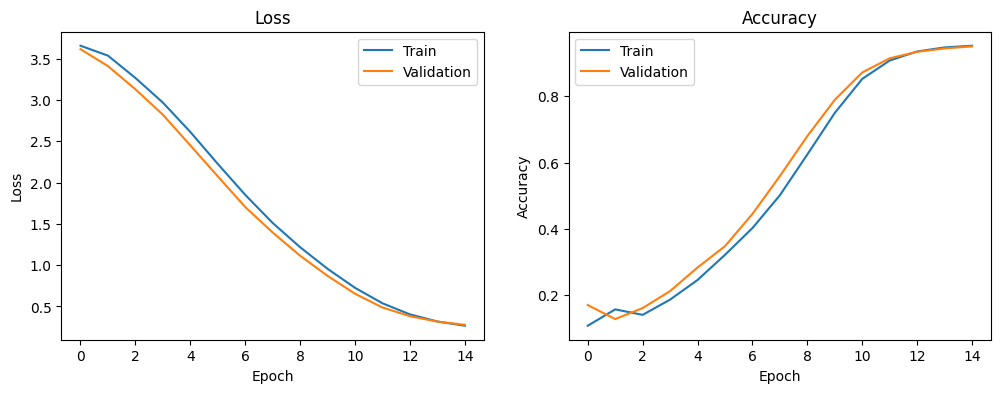

In [12]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'])

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'])
plt.show()

### Step 6 — Generate a new sequence (greedy)

**Q. At each step, which time-step’s prediction do you keep, and how do you update the input window for the next step?**
We keep the last step's prediction (`-1`). To update, we discard the first step of the input window and append the one-hot encoded vector of the newly generated note at the end of the window.

In [20]:
def generate_music_sampled(model, start_sequence, num_generated_notes=40, temperature=1.0):
    current = np.copy(start_sequence)
    generated = []
    for _ in range(num_generated_notes):
        pred = model.predict(current, verbose=0)
        logits = np.log(pred[0, -1, :] + 1e-8) / temperature
        exp_logits = np.exp(logits)
        probs = exp_logits / np.sum(exp_logits)
        next_note = np.random.choice(len(probs), p=probs)
        generated.append(next_note)
        new_note_one_hot = to_categorical([next_note], num_classes=40)
        new_note_one_hot = np.expand_dims(new_note_one_hot, axis=0)
        current = np.concatenate([current[:, 1:, :], new_note_one_hot], axis=1)
    return generated

sampled_notes = generate_music_sampled(model, start_seq, temperature=1.2)
print("Sampled Notes:", sampled_notes)

Sampled Notes: [38, 5, 5, 18, 29, 36, 2, 0, 0, 14, 35, 2, 33, 0, 0, 39, 14, 33, 9, 35, 9, 9, 4, 29, 25, 0, 6, 17, 2, 35, 37, 37, 15, 4, 4, 30, 20, 6, 28, 22]


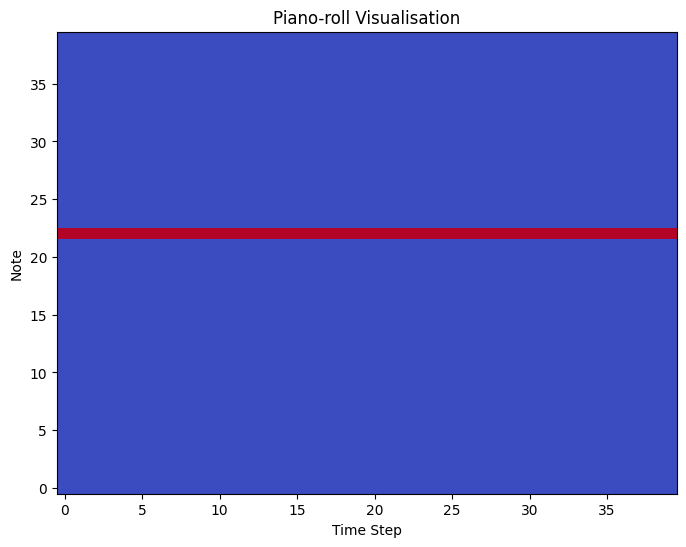

In [16]:
piano_roll = np.zeros((40, 40))
for t, note in enumerate(generated_notes):
    piano_roll[note, t] = 1

plt.figure(figsize=(8, 6))
plt.imshow(piano_roll, aspect='auto', cmap='coolwarm', origin='lower')
plt.xlabel('Time Step')
plt.ylabel('Note')
plt.title('Piano-roll Visualisation')
plt.show()